In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')

DRIVE_DATASET_FOLDER = "/content/drive/MyDrive/garbage_datasets"

print("📂 Archivos ZIP disponibles en Drive:")
zip_files = [f for f in os.listdir(DRIVE_DATASET_FOLDER) if f.endswith('.zip')]
for i, f in enumerate(zip_files):
    size_mb = os.path.getsize(os.path.join(DRIVE_DATASET_FOLDER, f)) / (1024*1024)
    print(f"{i}: {f} ({size_mb:.2f} MB)")

# Selecciona el archivo (cambia el índice si es diferente)
ZIP_INDEX = 0  # normalmente el más reciente
ZIP_FILENAME = zip_files[ZIP_INDEX]
ZIP_PATH = os.path.join(DRIVE_DATASET_FOLDER, ZIP_FILENAME)
print(f"\n✅ Usando: {ZIP_FILENAME}")

Mounted at /content/drive
📂 Archivos ZIP disponibles en Drive:
0: yolo_dataset_20260702_171802.zip (526.70 MB)

✅ Usando: yolo_dataset_20260702_171802.zip


In [2]:
import zipfile
import os
import shutil
import glob

EXTRACT_BASE = "/content"
TARGET_DIR = os.path.join(EXTRACT_BASE, "yolo_dataset")

# Eliminar carpeta destino si existe
if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

print(f"⏳ Descomprimiendo {ZIP_FILENAME}...")
temp_dir = os.path.join(EXTRACT_BASE, "temp_extract")
os.makedirs(temp_dir, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(temp_dir)

print("✅ Descompresión completada. Buscando la carpeta correcta...")

# Inspeccionar el contenido de temp_dir
items = os.listdir(temp_dir)
print(f"Contenido de temp_dir: {items}")

# Función para buscar recursivamente una carpeta que contenga 'images' y 'labels'
def find_dataset_folder(base_dir, target_name="yolo_dataset"):
    for root, dirs, files in os.walk(base_dir):
        if os.path.basename(root) == target_name:
            # Verificar que contiene images y labels
            if os.path.isdir(os.path.join(root, "images")) and os.path.isdir(os.path.join(root, "labels")):
                return root
    # Si no, buscar cualquier carpeta que contenga images y labels
    for root, dirs, files in os.walk(base_dir):
        if os.path.isdir(os.path.join(root, "images")) and os.path.isdir(os.path.join(root, "labels")):
            return root
    return None

found_path = find_dataset_folder(temp_dir)
if found_path:
    print(f"✅ Estructura de dataset encontrada en: {found_path}")
    # Mover al destino final
    shutil.move(found_path, TARGET_DIR)
    # Eliminar temp_dir (ya no necesitamos)
    shutil.rmtree(temp_dir)
    print(f"✅ Dataset movido a {TARGET_DIR}")
else:
    # Si no encontramos, asumimos que los archivos están directamente en temp_dir
    # y los movemos manualmente
    print("⚠️ No se encontró la carpeta 'yolo_dataset'. Moviendo todo a la carpeta destino...")
    os.makedirs(TARGET_DIR, exist_ok=True)
    for item in os.listdir(temp_dir):
        src = os.path.join(temp_dir, item)
        dst = os.path.join(TARGET_DIR, item)
        shutil.move(src, dst)
    shutil.rmtree(temp_dir)
    print(f"✅ Contenido movido a {TARGET_DIR}")

# Verificación final
if os.path.exists(TARGET_DIR):
    print("📁 Estructura final:")
    for root, dirs, files in os.walk(TARGET_DIR):
        level = root.replace(TARGET_DIR, '').count(os.sep)
        indent = ' ' * 2 * level
        print(f'{indent}{os.path.basename(root)}/')
        if level < 2:
            for f in files[:3]:
                print(f'{indent}  {f}')
            if len(files) > 3:
                print(f'{indent}  ... y {len(files)-3} más')
else:
    print("❌ ERROR CRÍTICO: No se pudo crear /content/yolo_dataset")

⏳ Descomprimiendo yolo_dataset_20260702_171802.zip...
✅ Descompresión completada. Buscando la carpeta correcta...
Contenido de temp_dir: ['content']
✅ Estructura de dataset encontrada en: /content/temp_extract/content/yolo_dataset
✅ Dataset movido a /content/yolo_dataset
📁 Estructura final:
yolo_dataset/
  labels/
    test/
    val/
    train/
  images/
    test/
    val/
    train/


In [3]:
# Desinstalar versiones conflictivas
!pip uninstall -y ultralytics torch torchvision

# Instalar versiones específicas que sabemos que funcionan juntas
!pip install torch==2.3.0 torchvision==0.18.0
!pip install ultralytics==8.2.0

print("✅ Instalación completada. Reinicia el runtime (Entorno de ejecución → Reiniciar sesión) y luego vuelve a ejecutar desde la celda de montaje de Drive.")

Found existing installation: torch 2.11.0+cpu
Uninstalling torch-2.11.0+cpu:
  Successfully uninstalled torch-2.11.0+cpu
Found existing installation: torchvision 0.26.0+cpu
Uninstalling torchvision-0.26.0+cpu:
  Successfully uninstalled torchvision-0.26.0+cpu
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 779.1/779.1 MB 792.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 93.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 66.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━

-----

In [21]:
import os
import cv2
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Ruta base donde se encuentra tu notebook y la carpeta 'modelos'
# Basado en la inspección de tu Drive, la carpeta 'Clasificación_basura' está directamente bajo MyDrive
# y la carpeta 'modelos_yolo' también está directamente bajo MyDrive.
BASE_DIR = "/content/drive/MyDrive/Clasificación_basura/" # Cambiamos BASE_DIR a la raíz de MyDrive para flexibilidad

# Ruta al modelo ONNX
# Asumiendo que el modelo 'detector.onnx' está dentro de la carpeta 'modelos_yolo' en tu MyDrive
model_path = os.path.join(BASE_DIR, "modelos", "detector.onnx")

# Ruta al directorio de test
# El dataset fue descomprimido en /content/yolo_dataset
DATASET_PATH = "/content/yolo_dataset"
test_dir = os.path.join(DATASET_PATH, 'images', 'test')

# Comprobar que existen
if not os.path.exists(model_path):
    raise FileNotFoundError(f"No se encontró el modelo en: {model_path}. Por favor, verifica la ruta correcta.")
if not os.path.exists(test_dir):
    raise FileNotFoundError(f"No se encontró el directorio de test en: {test_dir}. Por favor, asegúrate de que el dataset se haya descomprimido correctamente y esta ruta sea válida.")

print(f"Ruta del modelo: {model_path}")
print(f"Ruta del directorio de test: {test_dir}")

Ruta del modelo: /content/drive/MyDrive/Clasificación_basura/modelos/detector.onnx
Ruta del directorio de test: /content/yolo_dataset/images/test


In [22]:
# Cargar modelo ONNX
model = YOLO(model_path, task='detect')  # task='detect' es opcional
print("Modelo ONNX cargado correctamente.")

Modelo ONNX cargado correctamente.


Probando con: syn_00001826.jpg

image 1/1 /content/yolo_dataset/images/test/syn_00001826.jpg: 640x640 1 cardboard, 436.3ms
Speed: 12.6ms preprocess, 436.3ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


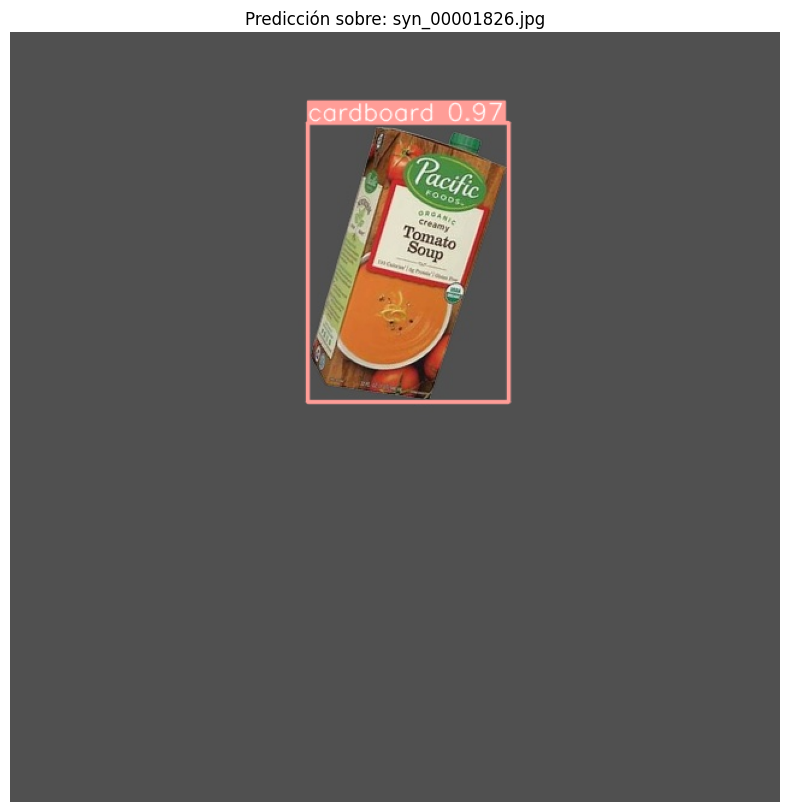

Cajas detectadas:
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([1.])
conf: tensor([0.9657])
data: tensor([[247.8429,  75.8838, 414.8982, 307.6600,   0.9657,   1.0000]])
id: None
is_track: False
orig_shape: (640, 640)
shape: torch.Size([1, 6])
xywh: tensor([[331.3705, 191.7719, 167.0553, 231.7763]])
xywhn: tensor([[0.5178, 0.2996, 0.2610, 0.3622]])
xyxy: tensor([[247.8429,  75.8838, 414.8982, 307.6600]])
xyxyn: tensor([[0.3873, 0.1186, 0.6483, 0.4807]])


In [24]:
# Listar imágenes .jpg en test_dir
test_imgs = [f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

if not test_imgs:
    raise ValueError("No hay imágenes en el directorio de test.")

# Elegir una al azar
sample = random.choice(test_imgs)
sample_path = os.path.join(test_dir, sample)
print(f"Probando con: {sample}")

# Ejecutar inferencia
results = model(sample_path)

# Obtener la imagen anotada
annotated = results[0].plot()  # imagen en BGR

# Mostrar con matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title(f"Predicción sobre: {sample}")
plt.show()

# Mostrar información de las cajas detectadas
if results[0].boxes is not None:
    print("Cajas detectadas:")
    print(results[0].boxes)
else:
    print("No se detectaron objetos en esta imagen.")

---

In [32]:
import onnxruntime as ort
import numpy as np
import cv2

session = ort.InferenceSession(model_path)

img = cv2.imread(sample_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = img.astype(np.float32) / 255.0
img = np.transpose(img, (2,0,1))
img = np.expand_dims(img,0)

output = session.run(None, {session.get_inputs()[0].name: img})[0]

print(output.shape)

print(output[0,:,0])      # primera predicción
print(output[0,:,100])    # predicción 100
print(output[0,:,5000])   # predicción 5000

(1, 10, 8400)
[     18.423      12.575      38.088      25.962  8.9407e-08  1.7881e-07  1.1921e-07  1.7881e-07  1.1921e-07  1.4901e-07]
[     169.99      9.4486      152.09      20.119  2.9802e-08  1.4901e-07           0  1.4901e-07           0  8.9407e-08]
[     323.54      494.85      39.176      46.011           0  8.9407e-08  5.9605e-08  2.9802e-08  2.9802e-08  2.9802e-08]


In [33]:
print(output.min(), output.max())

0.0 635.7534


In [34]:
pred = output[0].T

scores = pred[:,4:]

best = np.max(scores, axis=1)

idx = np.argmax(best)

print(idx)

print(pred[idx])

8149
[     331.37      191.77      167.06      231.78  1.1921e-06     0.96573   1.049e-05  2.2471e-05  3.6359e-06  5.0068e-06]
